In [1]:

#● Write a program to sharpen the input image using:   
%pip install opencv-python numpy matplotlib 

INFO: pip is looking at multiple versions of contourpy to determine which version is compatible with other requirements. This could take a while.
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
   -- ------------------------------------- 0.8/12.6 MB 3.0 MB/s eta 0:00:04
   ----- ---------------------------------- 1.6/12.6 MB 3.2 MB/s eta 0:00:04
   ------ --------------------------------- 2.1/12.6 MB 2.9 MB/s eta 0:00:04
   -------- ------------------------------- 2.6/12.6 MB 2.8 MB/s eta 0:00:04
   ---------- ----------------------------- 3.1/12.6 MB 2.8 MB/s eta 0:00:04
   ---------- ----------------------------- 3.4/12.6 MB 2.9 MB/s eta 0:00:04
   ------------- -------------------------- 4.2/12.6 MB 2.7 MB/s eta 0:00:04
   --------------- ------------------------ 5.0/12.6 MB 2.8 MB/s eta 0:00:03
   ------------------ --------------------- 5.8/12.6 MB 2.8 MB/s eta 0:00:03
   ------------------

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.5 which is incompatible.


<>:3: SyntaxWarning: invalid escape sequence '\d'
<>:3: SyntaxWarning: invalid escape sequence '\d'
C:\Users\saraj\AppData\Local\Temp\ipykernel_18412\2198073191.py:3: SyntaxWarning: invalid escape sequence '\d'
  img = cv2.imread("D:\doll.jpg")


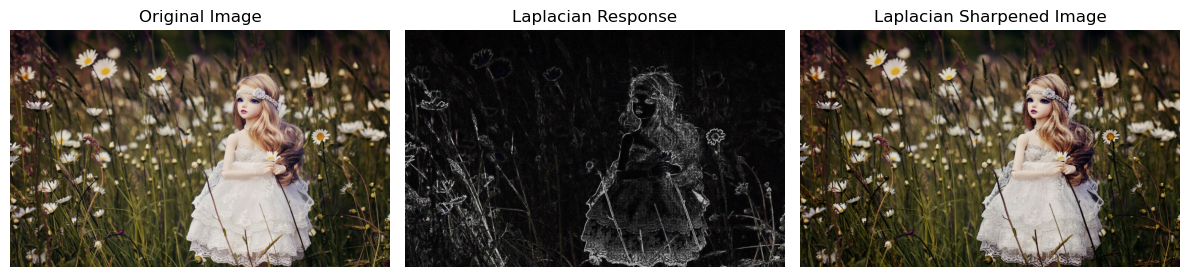

Laplacian sharpening completed.
Output saved as laplacian_sharpened.jpg


In [5]:
import cv2
import matplotlib.pyplot as plt
img = cv2.imread("D:\doll.jpg")

if img is None:
    raise FileNotFoundError("Please place input.jpg in the same folder.")

original = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
laplacian = cv2.Laplacian(img, cv2.CV_64F, ksize=3)
laplacian_abs = cv2.convertScaleAbs(laplacian)

sharpened = cv2.addWeighted(
    img, 1.0, laplacian_abs, -0.5, 0
)

sharpened_rgb = cv2.cvtColor(sharpened, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(laplacian_abs, cv2.COLOR_BGR2RGB))
plt.title("Laplacian Response")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(sharpened_rgb)
plt.title("Laplacian Sharpened Image")
plt.axis("off")
plt.tight_layout()
plt.show()

cv2.imwrite("laplacian_sharpened.jpg", sharpened)
print("Laplacian sharpening completed.")
print("Output saved as laplacian_sharpened.jpg")

<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
C:\Users\saraj\AppData\Local\Temp\ipykernel_18412\2707638647.py:6: SyntaxWarning: invalid escape sequence '\d'
  img = cv2.imread("D:\doll.jpg")


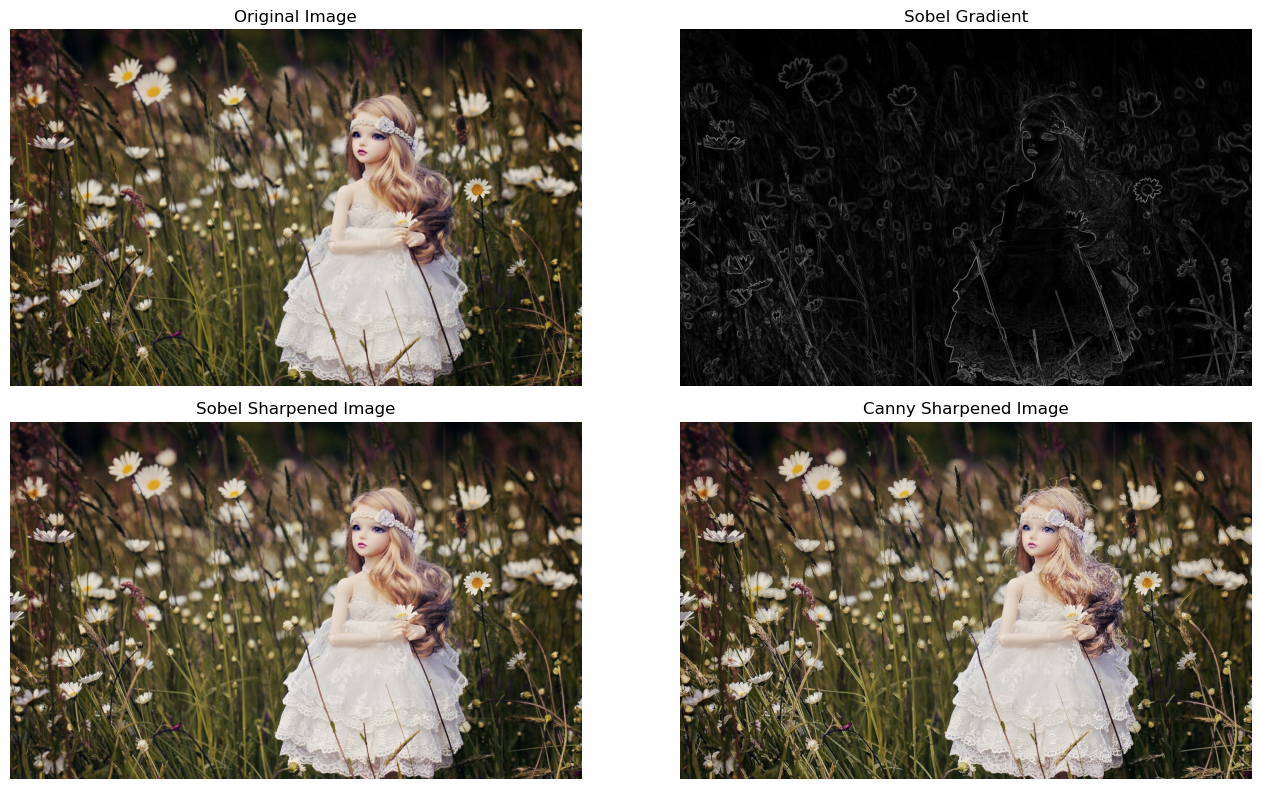

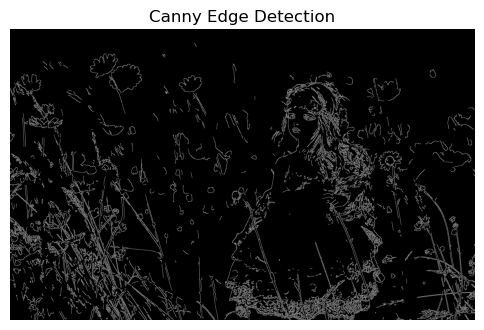

Sobel sharpening completed.
Canny edge detection and sharpening completed.
Output images saved successfully.


In [7]:
#2. Gradient operators of Sobel and Canny edge detector 
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("D:\doll.jpg")

if img is None:
    raise FileNotFoundError("Please place input.jpg in the same folder.")

original = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

gradient = np.sqrt(sobel_x**2 + sobel_y**2)

gradient = cv2.normalize(
    gradient, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

sobel_edges = cv2.cvtColor(gradient, cv2.COLOR_GRAY2BGR)

sobel_sharpened = cv2.addWeighted(
    img, 1.0, sobel_edges, 0.4, 0
)
canny_edges = cv2.Canny(gray, 100, 200)
canny_edges_color = cv2.cvtColor(
    canny_edges, cv2.COLOR_GRAY2BGR
)

canny_sharpened = cv2.addWeighted(
    img, 1.0, canny_edges_color, 0.5, 0
)
plt.figure(figsize=(14, 8))
plt.subplot(2, 2, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(gradient, cmap="gray")
plt.title("Sobel Gradient")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(cv2.cvtColor(sobel_sharpened, cv2.COLOR_BGR2RGB))
plt.title("Sobel Sharpened Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(canny_sharpened, cv2.COLOR_BGR2RGB))
plt.title("Canny Sharpened Image")
plt.axis("off")

plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
plt.imshow(canny_edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")
plt.show()
cv2.imwrite("sobel_sharpened.jpg", sobel_sharpened)
cv2.imwrite("canny_edges.jpg", canny_edges)
cv2.imwrite("canny_sharpened.jpg", canny_sharpened)

print("Sobel sharpening completed.")
print("Canny edge detection and sharpening completed.")
print("Output images saved successfully.")

<>:5: SyntaxWarning: invalid escape sequence '\d'
<>:5: SyntaxWarning: invalid escape sequence '\d'
C:\Users\saraj\AppData\Local\Temp\ipykernel_18412\2239141279.py:5: SyntaxWarning: invalid escape sequence '\d'
  img = cv2.imread("D:\doll.jpg")


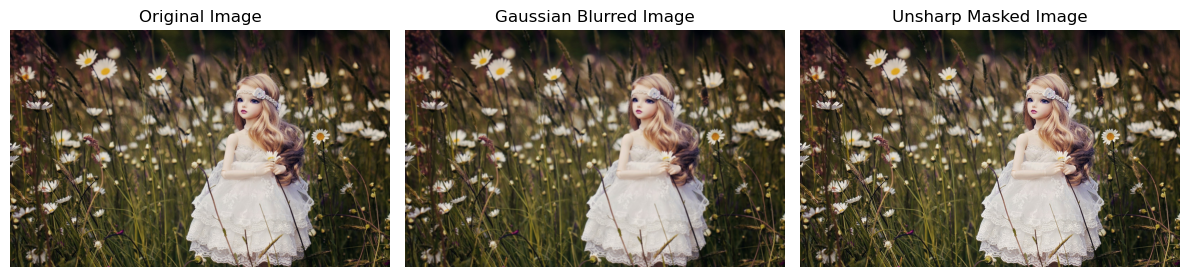

Gaussian blur applied: kernel = 5x5, sigma = 3
Unsharp masking completed.
Output saved as unsharp_masked.jpg


In [9]:
#3. Unsharp masking. To obtain blurred image, use the Gaussian filter of size 5x5 and sigma= 3 
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("D:\doll.jpg")
if img is None:
    raise FileNotFoundError("Please place input.jpg in the same folder.")

original = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
blurred = cv2.GaussianBlur(
    img, (5, 5), sigmaX=3
)

mask = cv2.subtract(img, blurred)
strength = 1.5
sharpened = cv2.addWeighted(
    img, 1.0, mask, strength, 0
)
blurred_rgb = cv2.cvtColor(blurred, cv2.COLOR_BGR2RGB)
sharpened_rgb = cv2.cvtColor(sharpened, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(blurred_rgb)
plt.title("Gaussian Blurred Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sharpened_rgb)
plt.title("Unsharp Masked Image")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite("gaussian_blurred.jpg", blurred)
cv2.imwrite("unsharp_masked.jpg", sharpened)

print("Gaussian blur applied: kernel = 5x5, sigma = 3")
print("Unsharp masking completed.")
print("Output saved as unsharp_masked.jpg")